# BAB IV — Hasil dan Pembahasan (CRISP-DM)
**Klasifikasi Software Inventory GLPI menggunakan TF-IDF dan tiga algoritma Machine Learning**

Notebook sederhana untuk **VS Code + Jupyter Notebook**. Setiap kode dipisahkan berdasarkan tahap pengerjaan. Kode 03 memilih kolom penting; **model hanya menggunakan teks nama software (`name`) sebagai fitur dan `label` sebagai target**.

**File input:** `RawData.csv` (12.390 baris, sudah memiliki label awal INCLUDE/EXCLUDE sesuai sembilan keluarga software yang ditetapkan pihak IT). **Folder output:** `Hasil/`.

> **Catatan penelitian:** label awal dibuat menggunakan kriteria kebutuhan IT, tetapi belum semuanya diverifikasi secara independen. Nilai evaluasi di notebook ini menunjukkan kesesuaian model dengan label awal, **bukan hasil akhir validasi ahli**.

> Pastikan `RawData.csv` berada di folder yang sama dengan notebook. Jalankan kode secara berurutan dari atas ke bawah.

## Persiapan

### Kode 01 — Import Library

In [4]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix

# Semua hasil disimpan di folder Hasil
Hasil = Path('Hasil')
Hasil.mkdir(exist_ok=True)

print('Library berhasil diimport.')
print('Folder hasil:', Hasil.resolve())

Library berhasil diimport.
Folder hasil: C:\Users\magang.tiga\Documents\CODE_GLPI\Hasil


### Kode 02 — Membaca Dataset yang Akan Digunakan

In [8]:

# Kode 02 — Membaca Dataset GLPI
import pandas as pd
from pathlib import Path

file = Path('RawData.csv')
RawData = None

for encoding in ['utf-8-sig', 'cp1252', 'latin1']:
    for separator in [',', ';', '\t']:
        try:
            data = pd.read_csv(
                file,
                encoding=encoding,
                sep=separator,
                dtype=str,
                keep_default_na=False
            )

            if {'name', 'label'}.issubset(data.columns):
                RawData = data
                print('Encoding:', encoding)
                print('Separator:', repr(separator))
                break

        except (UnicodeDecodeError, pd.errors.ParserError):
            continue

    if RawData is not None:
        break

if RawData is not None:
    print('Jumlah baris:', RawData.shape[0])
    print('Jumlah kolom:', RawData.shape[1])
    display(RawData.head(5))
else:
    print('CSV belum berhasil dibaca.')
    print('Lokasi file:', file.resolve())

    with open(file, encoding='cp1252') as f:
        for nomor, baris in enumerate(f, start=1):
            if nomor in [1, 2, 3, 16]:
                print(f'Baris {nomor}: {baris[:300]!r}')
            if nomor >= 16:
                break



Encoding: latin1
Separator: '\t'
Jumlah baris: 12390
Jumlah kolom: 26


,id,entities_id,is_recursive,name,comment,locations_id,users_id_tech,is_update,softwares_id,manufacturers_id,...,is_helpdesk_visible,softwarecategories_id,is_valid,date_creation,pictures,manufacturer_name,software_category_name,entity_name,label,keluarga_include
0,2,0,0,Microsoft Visio Standard 2013 Sngl OPEN 1 License,Microsoft Part Number : D86-05338,6,0,0,0,28,...,0,3,1,,,Microsoft,License,Root entity,INCLUDE,Microsoft Visio
1,3,0,0,Microsoft Office 2013 Sngl,Part Number 021 - 10257,6,0,0,0,28,...,0,3,1,,,Microsoft,License,Root entity,INCLUDE,Microsoft Office
2,4,0,0,Microsoft Windows Pro 8.1 Sngl,Part Number : FQC-08147\r\n,6,0,0,0,28,...,0,3,1,,,Microsoft,License,Root entity,INCLUDE,Microsoft Windows
3,6,0,0,Microsoft Windows Pro 8.1 Sngl,Part Number : FQC-08147,6,0,0,0,28,...,0,3,1,,,Microsoft,License,Root entity,INCLUDE,Microsoft Windows
4,7,0,0,Microsoft Office 2013 Sngl,Part Number : 021-10257,6,0,0,0,28,...,0,3,1,,,Microsoft,License,Root entity,INCLUDE,Microsoft Office


### Kode 03 — Memilih Kolom yang Digunakan

In [9]:
# Kolom penting untuk analisis dan klasifikasi
kolom_dipakai = ['id', 'name', 'manufacturer_name', 'software_category_name', 'label']
Data_Penelitian = RawData[kolom_dipakai].copy()

print('Kolom yang digunakan:', kolom_dipakai)
display(Data_Penelitian.head(5))
Data_Penelitian.to_csv(Hasil / 'Data_Kolom_Digunakan.csv', index=False, encoding='utf-8-sig')

Kolom yang digunakan: ['id', 'name', 'manufacturer_name', 'software_category_name', 'label']


,id,name,manufacturer_name,software_category_name,label
0,2,Microsoft Visio Standard 2013 Sngl OPEN 1 License,Microsoft,License,INCLUDE
1,3,Microsoft Office 2013 Sngl,Microsoft,License,INCLUDE
2,4,Microsoft Windows Pro 8.1 Sngl,Microsoft,License,INCLUDE
3,6,Microsoft Windows Pro 8.1 Sngl,Microsoft,License,INCLUDE
4,7,Microsoft Office 2013 Sngl,Microsoft,License,INCLUDE


## 4.1 Business Understanding
Tujuan penelitian ini adalah mengklasifikasikan Software Inventory GLPI menjadi dua kelas, yaitu **INCLUDE** (software yang perlu dipantau pada daftar utama IT) dan **EXCLUDE** (software selain daftar kebutuhan saat ini). Penelitian membandingkan Logistic Regression, Linear SVM, dan Multinomial Naive Bayes berbasis TF-IDF.

Penggunaan label berlandaskan sembilan keluarga produk kebutuhan IT. Output model bersifat rekomendasi, **bukan penghapusan data dari GLPI**.

## 4.2 Data Understanding

### Kode 04 — Informasi Dataset

In [10]:
print('Ukuran dataset:', Data_Penelitian.shape)
print('Nama kolom:', Data_Penelitian.columns.tolist())

tabel_info = pd.DataFrame({
    'Informasi': ['Jumlah Data', 'Jumlah Kolom', 'Nama Software Kosong', 'Jumlah ID Unik'],
    'Jumlah': [len(Data_Penelitian), len(Data_Penelitian.columns),
               Data_Penelitian['name'].str.strip().eq('').sum(),
               Data_Penelitian['id'].nunique()]
})
display(tabel_info)
tabel_info.to_csv(Hasil / 'Tabel_4_1_Informasi_Dataset.csv', index=False, encoding='utf-8-sig')

Ukuran dataset: (12390, 5)
Nama kolom: ['id', 'name', 'manufacturer_name', 'software_category_name', 'label']


,Informasi,Jumlah
0,Jumlah Data,12390
1,Jumlah Kolom,5
2,Nama Software Kosong,2
3,Jumlah ID Unik,12390


### Kode 05 — Mengecek Nilai Kosong

,Kolom,Jumlah_Kosong
0,software_category_name,3465
1,manufacturer_name,683
2,name,2
3,id,0
4,label,0


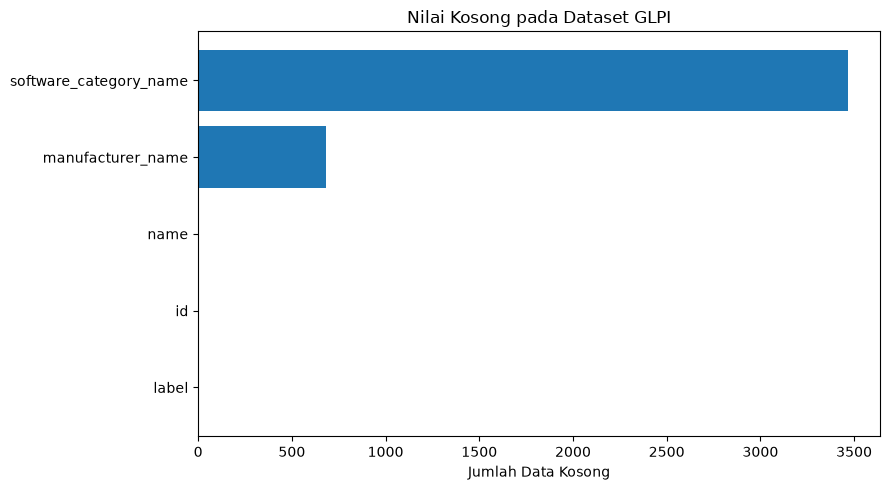

In [11]:
nilai_kosong = Data_Penelitian.apply(lambda kolom: kolom.astype(str).str.strip().eq('').sum())
tabel_kosong = nilai_kosong.sort_values(ascending=False).reset_index()
tabel_kosong.columns = ['Kolom', 'Jumlah_Kosong']

display(tabel_kosong.head(15))
tabel_kosong.to_csv(Hasil / 'Tabel_4_2_Nilai_Kosong.csv', index=False, encoding='utf-8-sig')

plt.figure(figsize=(9, 5))
plt.barh(tabel_kosong.head(12)['Kolom'][::-1], tabel_kosong.head(12)['Jumlah_Kosong'][::-1])
plt.title('Nilai Kosong pada Dataset GLPI')
plt.xlabel('Jumlah Data Kosong')
plt.tight_layout()
plt.savefig(Hasil / 'Gambar_4_1_Nilai_Kosong.png', dpi=200, bbox_inches='tight')
plt.show()

### Kode 06 — Mengecek Duplikasi Nama Software

Nama software unik: 9388
Baris dengan nama duplikat: 3002


,Nama_Software,Jumlah
0,Windows 10 Professional,68
1,Windows 10 Pro OLP NL,26
2,Office STD 2016 SNGL OLP NL PA,24
3,Microsoft Office 2013 Sngl,22
4,Microsoft Windows Pro 10 Sngl OLP License,18
5,Microsoft Windows Pro 8.1 Sngl,14
6,Claude,14
7,Microsoft Office 2016 Sngl OLP,13
8,Microsoft Office 2016 Sngl OLP NL FA,9
9,Windows Default Lock Screen,9


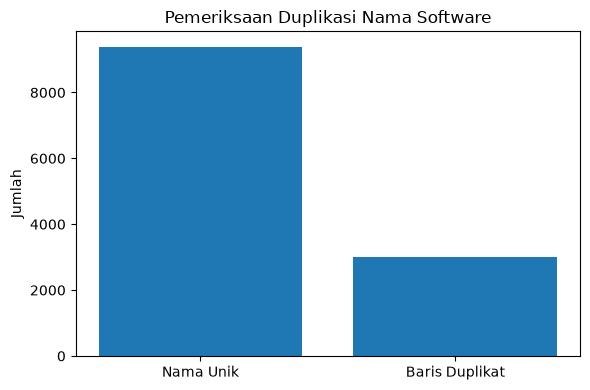

In [12]:
duplikat = Data_Penelitian['name'].duplicated().sum()
unik = Data_Penelitian['name'].nunique()
print('Nama software unik:', unik)
print('Baris dengan nama duplikat:', duplikat)

tabel_duplikat = Data_Penelitian['name'].value_counts().head(15).reset_index()
tabel_duplikat.columns = ['Nama_Software', 'Jumlah']
display(tabel_duplikat)
tabel_duplikat.to_csv(Hasil / 'Tabel_4_3_Nama_Software_Terbanyak.csv', index=False, encoding='utf-8-sig')

plt.figure(figsize=(6, 4))
plt.bar(['Nama Unik', 'Baris Duplikat'], [unik, duplikat])
plt.title('Pemeriksaan Duplikasi Nama Software')
plt.ylabel('Jumlah')
plt.tight_layout()
plt.savefig(Hasil / 'Gambar_4_2_Duplikasi_Nama.png', dpi=200, bbox_inches='tight')
plt.show()

### Kode 07 — Distribusi Kategori Asli GLPI

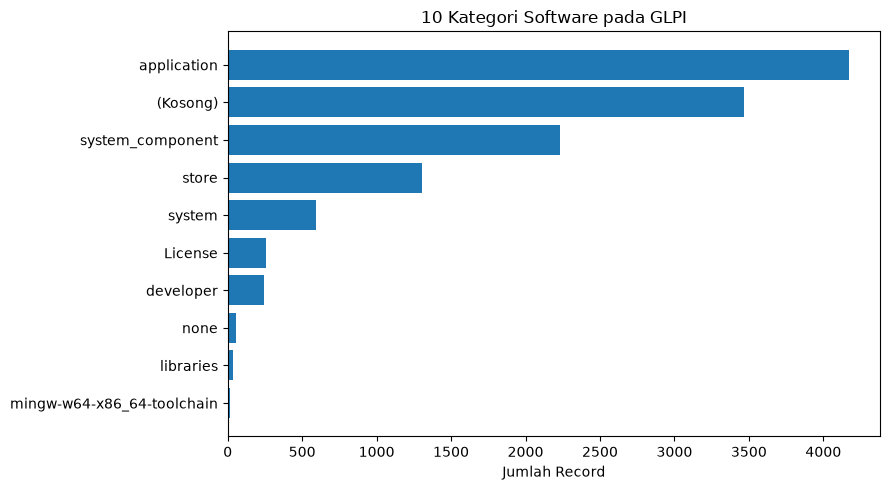

In [13]:
kategori = Data_Penelitian['software_category_name'].replace('', '(Kosong)').value_counts().head(10)

kategori.rename_axis('Kategori').reset_index(name='Jumlah').to_csv(
    Hasil / 'Tabel_4_4_Kategori_GLPI.csv', index=False, encoding='utf-8-sig'
)

plt.figure(figsize=(9, 5))
plt.barh(kategori.index[::-1], kategori.values[::-1])
plt.title('10 Kategori Software pada GLPI')
plt.xlabel('Jumlah Record')
plt.tight_layout()
plt.savefig(Hasil / 'Gambar_4_3_Kategori_GLPI.png', dpi=200, bbox_inches='tight')
plt.show()

### Kode 08 — Distribusi Label Awal INCLUDE dan EXCLUDE

,Jumlah
label,
EXCLUDE,11827
INCLUDE,563


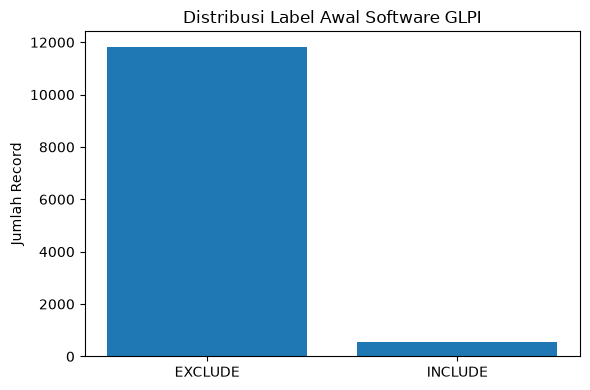

In [14]:
jumlah_label = Data_Penelitian['label'].value_counts()
display(jumlah_label.to_frame('Jumlah'))
jumlah_label.rename_axis('Label').reset_index(name='Jumlah').to_csv(
    Hasil / 'Tabel_4_5_Distribusi_Label_Awal.csv', index=False, encoding='utf-8-sig'
)

plt.figure(figsize=(6, 4))
plt.bar(jumlah_label.index, jumlah_label.values)
plt.title('Distribusi Label Awal Software GLPI')
plt.ylabel('Jumlah Record')
plt.tight_layout()
plt.savefig(Hasil / 'Gambar_4_4_Distribusi_Label.png', dpi=200, bbox_inches='tight')
plt.show()

## 4.3 Data Preparation
Di tahap ini kita membersihkan teks **nama software untuk kebutuhan model**, tanpa mengubah kolom `name` aslinya. Label sudah tersedia dalam `RawData`, jadi **tidak dilakukan pelabelan ulang**.

### Kode 09 — Text Preprocessing Nama Software

In [15]:
Data_Bersih = Data_Penelitian.copy()

# Lowercase, hapus spasi berlebih, tanpa menghapus nomor versi
Data_Bersih['nama_bersih'] = Data_Bersih['name'].str.lower().str.strip()
Data_Bersih['nama_bersih'] = Data_Bersih['nama_bersih'].str.replace(r'\s+', ' ', regex=True)

contoh = Data_Bersih[['name', 'nama_bersih']].head(20)
display(contoh)
contoh.to_csv(Hasil / 'Tabel_4_6_Contoh_Preprocessing.csv', index=False, encoding='utf-8-sig')
Data_Bersih.to_csv(Hasil / 'Data_Setelah_Preprocessing.csv', index=False, encoding='utf-8-sig')

,name,nama_bersih
0,Microsoft Visio Standard 2013 Sngl OPEN 1 License,microsoft visio standard 2013 sngl open 1 license
1,Microsoft Office 2013 Sngl,microsoft office 2013 sngl
2,Microsoft Windows Pro 8.1 Sngl,microsoft windows pro 8.1 sngl
3,Microsoft Windows Pro 8.1 Sngl,microsoft windows pro 8.1 sngl
4,Microsoft Office 2013 Sngl,microsoft office 2013 sngl
5,Microsoft Windows Pro 8.1 Sngl,microsoft windows pro 8.1 sngl
6,Microsoft Office 2013 Sngl,microsoft office 2013 sngl
7,Microsoft Windows Pro 8.1 Sngl,microsoft windows pro 8.1 sngl
8,Microsoft Office 2013 Sngl,microsoft office 2013 sngl
9,Adobe Pro 11.0,adobe pro 11.0


### Kode 10 — Memilih Data untuk Modeling

In [16]:
Data_Model = Data_Bersih[
    (Data_Bersih['nama_bersih'] != '') &
    (Data_Bersih['label'].isin(['INCLUDE', 'EXCLUDE']))
].copy()

print('Data sebelum diseleksi:', len(Data_Bersih))
print('Data siap modeling:', len(Data_Model))
print('Data tidak dipakai modeling:', len(Data_Bersih) - len(Data_Model))
print(Data_Model['label'].value_counts())

Data_Model.to_csv(Hasil / 'Data_Siap_Modeling.csv', index=False, encoding='utf-8-sig')

Data sebelum diseleksi: 12390
Data siap modeling: 12388
Data tidak dipakai modeling: 2
label
EXCLUDE    11825
INCLUDE      563
Name: count, dtype: int64


## 4.4 Modeling
Pembagian data mempertahankan **nama software yang sama di kelompok yang sama**, agar nama identik tidak muncul sekaligus pada train dan test. Data latih hanya digunakan untuk membangun TF-IDF dan model.

### Kode 11 — Membagi Data Training dan Testing (80:20)

In [17]:
pembagi = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_train, idx_test = next(pembagi.split(
    Data_Model, Data_Model['label'], groups=Data_Model['nama_bersih']
))

Train = Data_Model.iloc[idx_train].copy()
Test = Data_Model.iloc[idx_test].copy()

print('Jumlah training:', len(Train))
print('Jumlah testing:', len(Test))
print('Label training:')
print(Train['label'].value_counts())
print('Label testing:')
print(Test['label'].value_counts())

Train.to_csv(Hasil / 'Data_Training.csv', index=False, encoding='utf-8-sig')
Test.to_csv(Hasil / 'Data_Testing.csv', index=False, encoding='utf-8-sig')

Jumlah training: 9901
Jumlah testing: 2487
Label training:
label
EXCLUDE    9505
INCLUDE     396
Name: count, dtype: int64
Label testing:
label
EXCLUDE    2320
INCLUDE     167
Name: count, dtype: int64


### Kode 12 — Pembobotan TF-IDF

In [18]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train = tfidf.fit_transform(Train['nama_bersih'])
X_test = tfidf.transform(Test['nama_bersih'])
y_train = Train['label']
y_test = Test['label']

print('Ukuran TF-IDF training:', X_train.shape)
print('Ukuran TF-IDF testing:', X_test.shape)

fitur = pd.DataFrame({'Fitur_TFIDF': tfidf.get_feature_names_out()})
display(fitur.head(15))
fitur.to_csv(Hasil / 'Tabel_4_7_Fitur_TFIDF.csv', index=False, encoding='utf-8-sig')

Ukuran TF-IDF training: (9901, 6951)
Ukuran TF-IDF testing: (2487, 6951)


,Fitur_TFIDF
0,00
1,00 00
2,00 cpr
3,00 uwpdesktop
4,00 x64
5,0027
6,003
7,01
8,01 01
9,01 18


### Kode 13 — Training Logistic Regression

In [19]:
model_lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model_lr.fit(X_train, y_train)
pred_lr = model_lr.predict(X_test)
print('Training Logistic Regression selesai.')

Training Logistic Regression selesai.


### Kode 14 — Training Linear SVM

In [20]:
model_svm = LinearSVC(class_weight='balanced', random_state=42)
model_svm.fit(X_train, y_train)
pred_svm = model_svm.predict(X_test)
print('Training Linear SVM selesai.')

Training Linear SVM selesai.


### Kode 15 — Training Multinomial Naive Bayes

In [21]:
model_nb = MultinomialNB()
model_nb.fit(X_train, y_train)
pred_nb = model_nb.predict(X_test)
print('Training Multinomial Naive Bayes selesai.')

Training Multinomial Naive Bayes selesai.


## 4.5 Evaluation

### Kode 16 — Menghitung Accuracy, Precision, Recall, F1-Score

In [22]:
nama_model = ['Logistic Regression', 'Linear SVM', 'Multinomial Naive Bayes']
semua_prediksi = [pred_lr, pred_svm, pred_nb]

hasil = []
for nama, pred in zip(nama_model, semua_prediksi):
    hasil.append({
        'Model': nama,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision_Macro': precision_score(y_test, pred, average='macro', zero_division=0),
        'Recall_Macro': recall_score(y_test, pred, average='macro', zero_division=0),
        'F1_Macro': f1_score(y_test, pred, average='macro', zero_division=0),
        'Recall_INCLUDE': recall_score(y_test, pred, labels=['INCLUDE'], average='macro', zero_division=0)
    })

Hasil_Evaluasi = pd.DataFrame(hasil).sort_values('F1_Macro', ascending=False)
display(Hasil_Evaluasi.round(4))
Hasil_Evaluasi.to_csv(Hasil / 'Tabel_4_8_Evaluasi_Tiga_Model.csv', index=False, encoding='utf-8-sig')

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Recall_INCLUDE
1,Linear SVM,0.9948,0.9683,0.9916,0.9796,0.9880
0,Logistic Regression,0.9891,0.9321,0.9914,0.9595,0.9940
2,Multinomial Naive Bayes,0.9578,0.9784,0.6856,0.7597,0.3713


### Kode 17 — Grafik Perbandingan Tiga Model

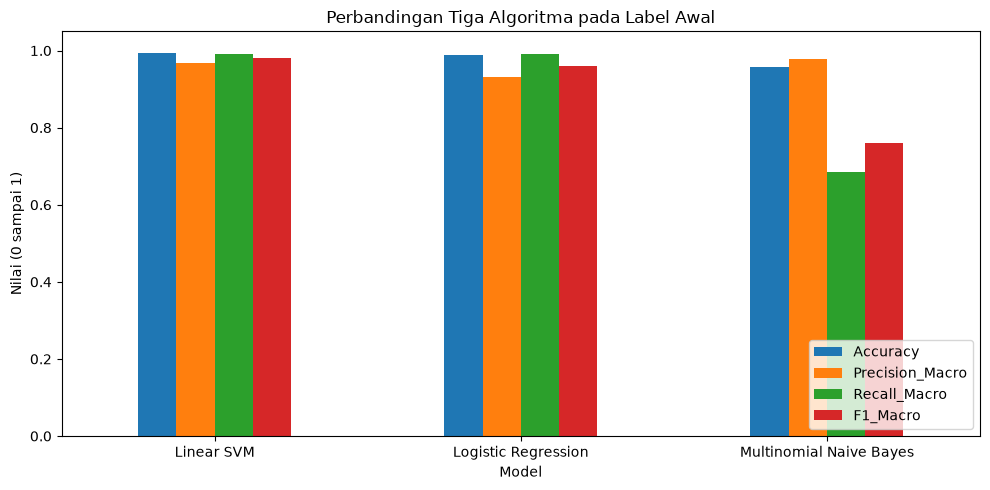

In [23]:
grafik = Hasil_Evaluasi.set_index('Model')[['Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Macro']]
grafik.plot(kind='bar', figsize=(10, 5), rot=0)
plt.title('Perbandingan Tiga Algoritma pada Label Awal')
plt.ylabel('Nilai (0 sampai 1)')
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(Hasil / 'Gambar_4_5_Perbandingan_Model.png', dpi=200, bbox_inches='tight')
plt.show()

### Kode 18 — Confusion Matrix untuk Setiap Model

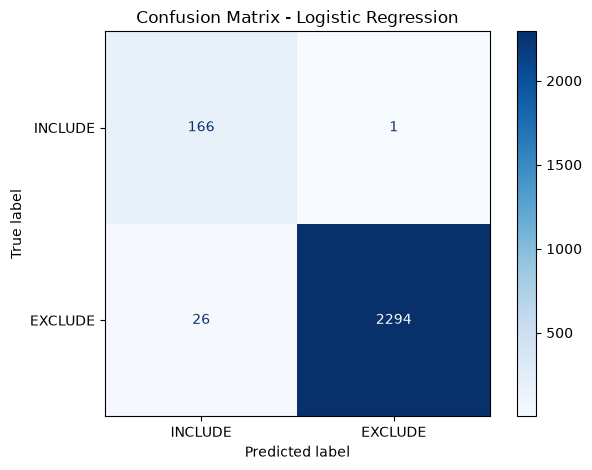

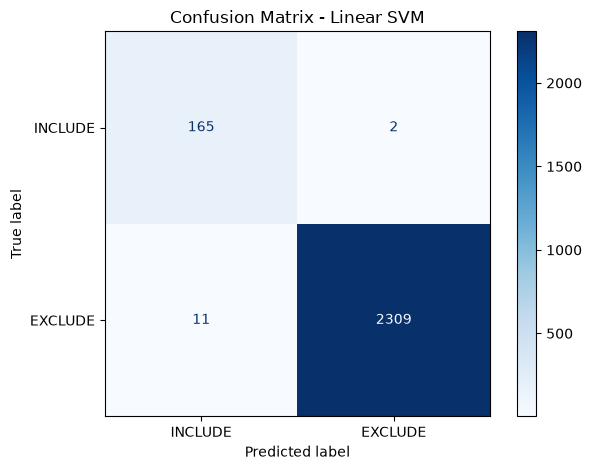

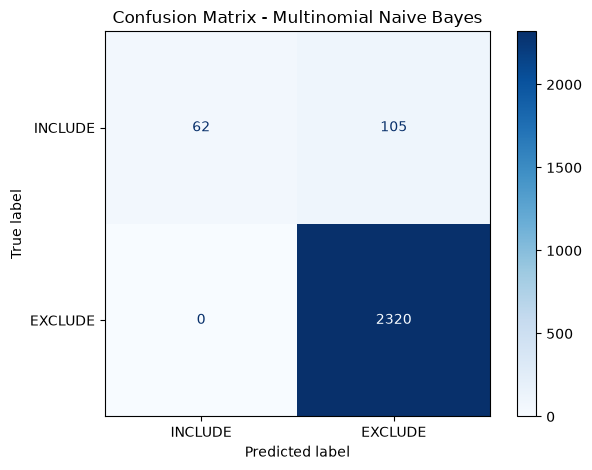

In [24]:
for nama, pred in zip(nama_model, semua_prediksi):
    cm = confusion_matrix(y_test, pred, labels=['INCLUDE', 'EXCLUDE'])
    grafik_cm = ConfusionMatrixDisplay(cm, display_labels=['INCLUDE', 'EXCLUDE'])
    grafik_cm.plot(cmap='Blues', values_format='d')
    plt.title('Confusion Matrix - ' + nama)
    plt.tight_layout()
    nama_file = nama.replace(' ', '_')
    plt.savefig(Hasil / ('Gambar_4_6_CM_' + nama_file + '.png'), dpi=200, bbox_inches='tight')
    plt.show()

    laporan = classification_report(y_test, pred, output_dict=True, zero_division=0)
    pd.DataFrame(laporan).transpose().to_csv(
        Hasil / ('Tabel_Classification_Report_' + nama_file + '.csv'), encoding='utf-8-sig'
    )

### Kode 19 — Menyimpan Prediksi Data Testing

In [25]:
Prediksi_Testing = Test[['id', 'name', 'label']].copy()
Prediksi_Testing['Prediksi_LR'] = pred_lr
Prediksi_Testing['Prediksi_SVM'] = pred_svm
Prediksi_Testing['Prediksi_NB'] = pred_nb

display(Prediksi_Testing.head(10))
Prediksi_Testing.to_csv(Hasil / 'Prediksi_Data_Testing.csv', index=False, encoding='utf-8-sig')

,id,name,label,Prediksi_LR,Prediksi_SVM,Prediksi_NB
0,2,Microsoft Visio Standard 2013 Sngl OPEN 1 License,INCLUDE,INCLUDE,INCLUDE,INCLUDE
1,3,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE,INCLUDE,INCLUDE
4,7,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE,INCLUDE,INCLUDE
6,9,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE,INCLUDE,INCLUDE
8,11,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE,INCLUDE,INCLUDE
12,25,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE,INCLUDE,INCLUDE
13,26,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE,INCLUDE,INCLUDE
16,29,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE,INCLUDE,INCLUDE
18,32,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE,INCLUDE,INCLUDE
20,34,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE,INCLUDE,INCLUDE


> **Interpretasi:** label dalam input saat ini berasal dari aturan berdasarkan kebutuhan software yang ditetapkan Pak Widi. Oleh karena itu angka evaluasi **belum mengukur kecocokan terhadap label ahli yang diverifikasi satu per satu**, dan tidak boleh dituliskan sebagai hasil akhir validasi ahli di skripsi.

## 4.6 Deployment (Prototype Batch)
Ketiga model dilatih ulang pada seluruh baris berlabel untuk menghasilkan rekomendasi. **REVIEW adalah status jika ketiga model tidak sepakat**, bukan kelas training ketiga. Tidak ada aturan GLPI yang diubah secara otomatis.

### Kode 20 — Menyimpan Model Akhir

In [26]:
import pandas as pd
import numpy as np
import joblib

from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

Hasil = Path('Hasil')
Hasil.mkdir(exist_ok=True)

In [27]:
# Latih ulang TF-IDF menggunakan semua data berlabel
TFIDF_Akhir = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_semua = TFIDF_Akhir.fit_transform(Data_Model['nama_bersih'])
y_semua = Data_Model['label']

Model_Akhir = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Linear SVM': LinearSVC(class_weight='balanced', random_state=42),
    'Multinomial Naive Bayes': MultinomialNB()
}

for nama, model in Model_Akhir.items():
    model.fit(X_semua, y_semua)
    joblib.dump(model, Hasil / ('Model_' + nama.replace(' ', '_') + '.joblib'))

joblib.dump(TFIDF_Akhir, Hasil / 'TFIDF_Akhir.joblib')
print('Tiga model dan TF-IDF berhasil disimpan di Hasil.')

Tiga model dan TF-IDF berhasil disimpan di Hasil.


### Kode 21 — Prediksi Semua Software dan Status REVIEW

In [28]:
Hasil_Prediksi = RawData.copy()
Hasil_Prediksi['nama_bersih'] = Hasil_Prediksi['name'].str.lower().str.strip()
Hasil_Prediksi['nama_bersih'] = Hasil_Prediksi['nama_bersih'].str.replace(r'\s+', ' ', regex=True)

# Untuk nama kosong, hasilnya langsung REVIEW
ada_nama = Hasil_Prediksi['nama_bersih'] != ''
Hasil_Prediksi['Prediksi_LR'] = ''
Hasil_Prediksi['Prediksi_SVM'] = ''
Hasil_Prediksi['Prediksi_NB'] = ''

X_prediksi = TFIDF_Akhir.transform(Hasil_Prediksi.loc[ada_nama, 'nama_bersih'])
Hasil_Prediksi.loc[ada_nama, 'Prediksi_LR'] = Model_Akhir['Logistic Regression'].predict(X_prediksi)
Hasil_Prediksi.loc[ada_nama, 'Prediksi_SVM'] = Model_Akhir['Linear SVM'].predict(X_prediksi)
Hasil_Prediksi.loc[ada_nama, 'Prediksi_NB'] = Model_Akhir['Multinomial Naive Bayes'].predict(X_prediksi)

sepakat = ((Hasil_Prediksi['Prediksi_LR'] == Hasil_Prediksi['Prediksi_SVM']) &
           (Hasil_Prediksi['Prediksi_LR'] == Hasil_Prediksi['Prediksi_NB']))
Hasil_Prediksi['Status_Prediksi'] = np.where(
    ada_nama & sepakat, Hasil_Prediksi['Prediksi_LR'], 'REVIEW'
)

print(Hasil_Prediksi['Status_Prediksi'].value_counts())
display(Hasil_Prediksi[['name', 'label', 'Status_Prediksi']].head(10))
Hasil_Prediksi.to_csv(Hasil / 'Hasil_Prediksi_Semua_Software.csv', index=False, encoding='utf-8-sig')

Status_Prediksi
EXCLUDE    11728
INCLUDE      411
REVIEW       251
Name: count, dtype: int64


,name,label,Status_Prediksi
0,Microsoft Visio Standard 2013 Sngl OPEN 1 License,INCLUDE,INCLUDE
1,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE
2,Microsoft Windows Pro 8.1 Sngl,INCLUDE,INCLUDE
3,Microsoft Windows Pro 8.1 Sngl,INCLUDE,INCLUDE
4,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE
5,Microsoft Windows Pro 8.1 Sngl,INCLUDE,INCLUDE
6,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE
7,Microsoft Windows Pro 8.1 Sngl,INCLUDE,INCLUDE
8,Microsoft Office 2013 Sngl,INCLUDE,INCLUDE
9,Adobe Pro 11.0,EXCLUDE,REVIEW


### Kode 22 — Ekspor Daftar INCLUDE, EXCLUDE, REVIEW

In [29]:
Daftar_Include = Hasil_Prediksi[Hasil_Prediksi['Status_Prediksi'] == 'INCLUDE']
Daftar_Exclude = Hasil_Prediksi[Hasil_Prediksi['Status_Prediksi'] == 'EXCLUDE']
Daftar_Review = Hasil_Prediksi[Hasil_Prediksi['Status_Prediksi'] == 'REVIEW']

Daftar_Include.to_csv(Hasil / 'Daftar_INCLUDE.csv', index=False, encoding='utf-8-sig')
Daftar_Exclude.to_csv(Hasil / 'Daftar_EXCLUDE.csv', index=False, encoding='utf-8-sig')
Daftar_Review.to_csv(Hasil / 'Daftar_REVIEW.csv', index=False, encoding='utf-8-sig')

with pd.ExcelWriter(Hasil / 'Hasil_Rekomendasi_Software.xlsx') as writer:
    Hasil_Prediksi.to_excel(writer, sheet_name='Semua', index=False)
    Daftar_Include.to_excel(writer, sheet_name='INCLUDE', index=False)
    Daftar_Exclude.to_excel(writer, sheet_name='EXCLUDE', index=False)
    Daftar_Review.to_excel(writer, sheet_name='REVIEW', index=False)

print('Daftar INCLUDE, EXCLUDE, REVIEW dan file Excel tersimpan di Hasil.')

Daftar INCLUDE, EXCLUDE, REVIEW dan file Excel tersimpan di Hasil.


### Kode 23 — Grafik Hasil Deployment

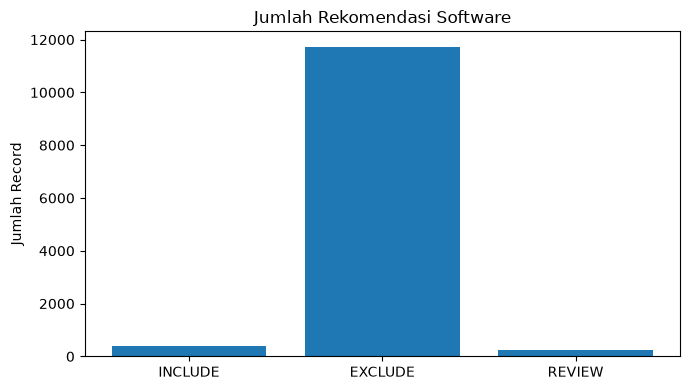

In [30]:
status = Hasil_Prediksi['Status_Prediksi'].value_counts().reindex(
    ['INCLUDE', 'EXCLUDE', 'REVIEW'], fill_value=0
)

plt.figure(figsize=(7, 4))
plt.bar(status.index, status.values)
plt.title('Jumlah Rekomendasi Software')
plt.ylabel('Jumlah Record')
plt.tight_layout()
plt.savefig(Hasil / 'Gambar_4_7_Rekomendasi_Software.png', dpi=200, bbox_inches='tight')
plt.show()

status.rename_axis('Status').reset_index(name='Jumlah').to_csv(
    Hasil / 'Tabel_4_9_Status_Rekomendasi.csv', index=False, encoding='utf-8-sig'
)

### Kode 24 — Melihat Semua File di Folder Hasil

In [31]:
semua_file = sorted([f.name for f in Hasil.iterdir() if f.is_file()])
print('Total file di folder Hasil:', len(semua_file))
for nama in semua_file:
    print('-', nama)

pd.DataFrame({'Nama_File': semua_file}).to_csv(
    Hasil / 'Daftar_File_Hasil.csv', index=False, encoding='utf-8-sig'
)

Total file di folder Hasil: 36
- Daftar_EXCLUDE.csv
- Daftar_INCLUDE.csv
- Daftar_REVIEW.csv
- Data_Kolom_Digunakan.csv
- Data_Setelah_Preprocessing.csv
- Data_Siap_Modeling.csv
- Data_Testing.csv
- Data_Training.csv
- Gambar_4_1_Nilai_Kosong.png
- Gambar_4_2_Duplikasi_Nama.png
- Gambar_4_3_Kategori_GLPI.png
- Gambar_4_4_Distribusi_Label.png
- Gambar_4_5_Perbandingan_Model.png
- Gambar_4_6_CM_Linear_SVM.png
- Gambar_4_6_CM_Logistic_Regression.png
- Gambar_4_6_CM_Multinomial_Naive_Bayes.png
- Gambar_4_7_Rekomendasi_Software.png
- Hasil_Prediksi_Semua_Software.csv
- Hasil_Rekomendasi_Software.xlsx
- Model_Linear_SVM.joblib
- Model_Logistic_Regression.joblib
- Model_Multinomial_Naive_Bayes.joblib
- Prediksi_Data_Testing.csv
- TFIDF_Akhir.joblib
- Tabel_4_1_Informasi_Dataset.csv
- Tabel_4_2_Nilai_Kosong.csv
- Tabel_4_3_Nama_Software_Terbanyak.csv
- Tabel_4_4_Kategori_GLPI.csv
- Tabel_4_5_Distribusi_Label_Awal.csv
- Tabel_4_6_Contoh_Preprocessing.csv
- Tabel_4_7_Fitur_TFIDF.csv
- Tabel_4_8_

---
**Catatan untuk BAB IV:** gunakan grafik dan tabel yang ada di `Hasil/`, tetapi jangan menyebut hasil prediksi sebagai perubahan langsung pada GLPI. Pengubahan hasil EXCLUDE menjadi XML rules adalah pekerjaan implementasi terpisah dan tetap membutuhkan verifikasi pihak IT. Model yang dievaluasi pada notebook ini belum memakai *ground truth* hasil verifikasi Pak Widi.